# Машинное обучение, ФКН ВШЭ

## Практическое домашнее задание 3.2  Продвинутая генерация признаков

### Общая информация

Дата выдачи: 23.02.2026

Мягкий дедлайн: 12.03.2026 23:59MSK

Жесткий дедлайн: 16.03.2026 23:59MSK

### О задании

В данном задании вы познакомитесь с менее тривиальными подходами для создания новых признаков в табличном машинном обучении. Вам понадобится подумать над тем, зачем мы делаем те или иные преобразования, научиться принимать решения, дающие наилучшие результаты, и узнать, как реализовывать их при помощи библиотек

### Оценивание и штрафы

См. базовую часть

### Формат сдачи
Задания сдаются через систему Anytask. Инвайт можно найти на странице курса. Присылать необходимо ноутбук с выполненным заданием. Сам ноутбук называйте в формате **homework-practice-03-advanced-Username.ipynb**, где Username — ваша фамилия.

### **Введение**

В этой части ноутбука задания посложнее дефолтного фит трансформа. Максимальная оценка за оба — 8 баллов, остальное вы можете получить, если примете участие в соревновании, и всего можете выбить аж 13 из 10. Тут ожидается больше самостоятельности, как от (почти) полноценной рабочей единицы:
- Вы **сами** решаете, что <font color="#cb9255">**хотите**</font> делать. Пункты можно делать частично, можно скипать или сделать часть, **максимум баллов ограничен двумя**. **Посмотрите на все из них**, прежде чем приступать
- Вы **сами** чистите данные, если чуете в них подвох (теперь они далеко не такие няшные)
- Вы **сами** <font color="#f68c9d">**обосновываете**</font> (в голове, если не указано явно), могут они вам вообще помочь или нет (часть пунктов явно сильнее других)

Все прочие пожелания по тому, как строить графики, на чём фиттить, а на чём предиктить, сохраняются, будьте внимательны. Во всех пунктах с 📈 нужно добиться хотя бы минимального улучшения, относительно бейзлайна (того, что вышло в части **base**) чтобы получить балл (даже если улучшение на 0.005)

Ещё раз обратите внимание, что **максимум за advanced часть — 2 балла**, делать всё не нужно, только самое приятное. Мы в вас верим!

### **Часть 4. Текста** (1.5 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/4/4f/Emoticon_blush.gif/revision/latest?cb=20180504011409">

В которой студент знакомится с внутренним миром дотеров

#### **Задание 4.1. Предобработка текста** (0.75 балла)

<span style="color:grey"><font size="1">Если вам когда-либо приходила в голову мысль, что создание Интернета было ошибкой, то, что ж, после этого задания сомнения могут отпасть.</font></span>

Для некоторых матчей имеется информация о том, что писали местные аборигены, в течение тех же **15 минут от начала матча**. К сожалению, доселе мы работали лишь с таблицами, а не с текстами, но не беда, простейшие подходы нейросетей не требуют, а в простых задачах, вроде бинарной классификации, работать будут не хуже

Откройте датафрейм `game_chat.csv`, выведите парочку текстов, посмотрите, как они устроены, как там хранятся множественные сообщения,  и так далее, что у нас есть, а чего, увы, нет

In [4]:
import pandas as pd

In [29]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
chat_df = pd.read_csv('game_chat.csv')

display(chat_df.sample(5))

longest_row = chat_df.loc[chat_df['radiant_chat'].str.len().idxmax()]
display(longest_row)


display(chat_df.info())

display(chat_df.isna().mean())

,match_id,radiant_chat,dire_chat
514149,524728,NaN,NaN
381630,323442,NaN,NaN
206922,635866,NaN,NaN
489243,67259,NaN,ENEMIGO
349545,104510,NaN,NaN


,596774
match_id,168526
radiant_chat,"IN THE SAME GAME, THE TOTAL PAUSE TIME CAN'T B..."
dire_chat,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 700838 entries, 0 to 700837
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   match_id      700838 non-null  int64 
 1   radiant_chat  90624 non-null   object
 2   dire_chat     90604 non-null   object
dtypes: int64(1), object(2)
memory usage: 16.0+ MB


None

,0
match_id,0.000000
radiant_chat,0.870692
dire_chat,0.870720


Дём дальше. Тексты нужно готовить, прежде чем пихать их в модель. Оценивать выбросы здесь довольно проблематично, в силу специфики дотерских сообщений, хотя вы, конечно, можете попытаться. Речь здесь про базовую предобработку.

Задача минимум, тут мы вам поможем:
- Разобраться с библиотекой `nltk` и разбить текст на токены — отдельные сущности, составляющие текст (чаще всего слова, но бывает и что-то другое, надо разобраться). Как бить текст — вопрос неоднозначный. В целом подойдёт любой способ, но какие-то [токенизаторы](https://www.nltk.org/api/nltk.tokenize.html) могут сразу покрыть часть проблем с текстами в задаче максимум
- Лемматизировать текст (привести слова к начальной форме). <br>
<font color="#cb9255">**Варианта два**</font>: манкипатчить [`pymorphy2`](https://pymorphy2.readthedocs.io/en/stable/) или откатывать версии (там вылезет ошибка, если у вас слишком новый питон), либо применять [`mystem`](https://pypi.org/project/pymystem3/), что может затянуться на несколько часов, зато лемматизация будет точнее

Задача максимум, тут вам нужно понять, как всё обработать, самим (включать-не включать, выкинуть-оставить — валидны **все** варианты, но только, если, есть, <font color="#f68c9d">**обоснование**</font>):
- повторы символов
- знаки препинания
- стоп-слова
- нижний регистр
  
Вам нужно пройтись по всем пунктам, не обязательно в этом порядке. Если найдёте что-то ещё — круто, молодцы, можно тоже пофиксить

<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** ну что, как обрабатываем текст?

**Ответ:**

1. Приводим слова к нижнему регистру, тем самым уменьшаем размер словаря.
2. Разбиваем текст на токены с помощью NLTK.
3. Удаляем знаки припинания, поскольку для нашей задачи они не должны нести пользы.
4. Сокращаем чрезмерные повторения символов, например гооооо -> гоо, опять же чтобы упростить словарь.
5. Лемматизируем русские слова с помощью морфологического анализатора.
6. Не удаляю стоп-слова, по типу коротких сообщений не, no, not...
7. Пустые сообщения заменяются пустыми строками. Сообщения Radiant и Dire обрабатываются отдель, поскольку их смысл может зависить от команды? (Не уверен)

In [6]:
%pip install pymorphy3 wordcloud

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 68.8 MB/s eta 0:00:00


In [7]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import re
import nltk
import pymorphy3

from functools import lru_cache
from nltk.tokenize import RegexpTokenizer

morph = pymorphy3.MorphAnalyzer()

tokenizer = RegexpTokenizer(
  r'[а-яё]+|[a-z]+|[\u4e00-\u9fff]+|\d+'
)

@lru_cache(maxsize=100000)
def lemmatize(token):
  # Лемматизируем только русские слова
  if re.fullmatch(r'[а-яё]+', token):
    return morph.parse(token)[0].normal_form # [0] selects the most probable form
  return token


def preprocessing(text: str):
    if not isinstance(text, str):
      return []

    text = text.lower()

    # Уменьшаем повторы букв
    text = re.sub(
      r'([a-zа-яё])\1{2,}',
      r'\1\1',
      text
    )

    # nltk-tokenization
    tokens = tokenizer.tokenize(text)

    # Lemmatization
    tokens = [lemmatize(token) for token in tokens]

    return tokens

# можете проверить, что делает ваша функция, на тесте ниже
print(preprocessing("Ляяя, ваша мама такая красивая, ну вылитый пудж)))0"))

['ляя', 'ваш', 'мама', 'такой', 'красивый', 'ну', 'вылитый', 'пуджа', '0']


#### 📈 **Задание 4.2. Векторизация** (0.5 балла)

Ура, если у вас получились токены, то наконец-то можно что-то закодировать, но как? Рад, что вы спросили. Читайте конспект семинаров или документацию

<table width="800" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="50%">
      <font color="#cb9255">CountVectorizer</font>
    </th>
    <th width="50%">
      <font color="#cb9255">TfIdfVectorizer</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Берёт и считает, сколько раз в тексте <br>
      встретилось то или иное слово. Похож <br>
      на наш энкодер из части 2.
      <br><br>
      <table border="1" cellpadding="4" cellspacing="0">
        <thead>
          <tr>
            <th scope="col">word_1</th>
            <th scope="col">word_2</th>
            <th scope="col">word_3</th>
            <th scope="col">...</th>
            <th scope="col">word_m</th>
          </tr>
        </thead>
        <tbody>
          <tr>
            <td>1</td>
            <td>0</td>
            <td>2</td>
            <td>...</td>
            <td>100</td>
          </tr>
        </tbody>
      </table>
    </td>
    <td valign="top">
      Более хитрая штука: вместе с количеством слов (tf)<br>
      считает их важность (idf). Слова, встречающиеся <br>
      во всех документах, считаются не важными<br>
      и зануляются (idf = log1).
      <br><br>
      <table border="1" cellpadding="4" cellspacing="0">
        <thead>
          <tr>
            <th scope="col"></th>
            <th scope="col">word_1</th>
            <th scope="col">word_2</th>
            <th scope="col">word_3</th>
            <th scope="col">...</th>
            <th scope="col">word_m</th>
          </tr>
        </thead>
        <tbody>
          <tr>
            <td><b>text_1</b></td>
            <td>1*log2</td>
            <td>0</td>
            <td>2*log2</td>
            <td>...</td>
            <td>100*log1</td>
          </tr>
          <tr>
            <td><b>text_2</b></td>
            <td>0</td>
            <td>10*log2</td>
            <td>0</td>
            <td>...</td>
            <td>100*log1</td>
          </tr>
        </tbody>
      </table>
    </td>
  </tr>
</table>


Оба векторайзера хороши, но у каждого из них есть <font color="#cb9255">**гиперпараметры**</font>. Естественно, они повлияют на качество, <font color="#cb9255">**можете подобрать их**</font> попозже, дефолтные тоже должны показать эффект

Обучите по векторайзеру на чатах Radiant и Dire. Приклейте результат к вашему датасету и обучите модель на всём получившемся великолепии (sparse формат убирать не рекомендуется)

In [8]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import numpy as np

train_df = pd.read_csv('matches_df_train.csv', parse_dates=['date'])

chat_df = pd.read_csv('game_chat.csv')

# Сопоставляем тексты с матчами по 'match_id'
chat_aligned = (
    chat_df
    .set_index('match_id')
    .reindex(train_df['match_id'].to_numpy())
    .reset_index(drop=True)
)

# Empty messages
chat_aligned[['radiant_chat', 'dire_chat']] = (
    chat_aligned[['radiant_chat', 'dire_chat']].fillna("")
)

# Применяем предобработку текста
radiant_texts = chat_aligned['radiant_chat'].map(
    lambda text: ' '.join(preprocessing(text))
)
dire_texts = chat_aligned['dire_chat'].map(
    lambda text: ' '.join(preprocessing(text))
)

display(radiant_texts.sample(3))
display(dire_texts.sample(3))

,radiant_chat
438692,
296573,
623862,


,dire_chat
281618,
352784,
607836,


In [9]:
X = pd.DataFrame(index=train_df.index)

# Признаки из первой части
X['region'] = train_df['region'].fillna('Unknown')
X['day_of_week'] = train_df['date'].dt.dayofweek.astype(str)
X['match_day'] = train_df['date'].dt.day
X['month'] = train_df['date'].dt.month
X['is_weekend'] = (
    train_df['date'].dt.dayofweek >= 5
).astype(int)

X['mmr_log'] = np.log1p(
    train_df['avg_mmr'].clip(lower=0)
)
X['mmr_missing'] = train_df['avg_mmr'].isna().astype(int)

# Новые признаки - активность чата
for side in ['radiant', 'dire']:
  text = chat_aligned[f'{side}_chat']
  has_chat = text.ne('')

  X[f'{side}_has_chat'] = has_chat.astype(int)
  X[f'{side}_messages'] = text.str.count(r'\|')
  X[f'{side}_chars'] = text.str.len()
  X[f'{side}_questions'] = text.str.count(r'\?')
  X[f'{side}_exclamations'] = text.str.count(r'!')

print(X.shape)
display(X.sample(5))

(641090, 17)


,region,day_of_week,match_day,month,is_weekend,mmr_log,mmr_missing,radiant_has_chat,radiant_messages,radiant_chars,radiant_questions,radiant_exclamations,dire_has_chat,dire_messages,dire_chars,dire_questions,dire_exclamations
43847,Europe West,3,18,1,0,NaN,1,0,0,0,0,0,0,0,0,0,0
172668,Europe West,1,6,8,0,7.597848,0,1,0,4,0,0,1,0,2,0,0
126825,SE Asia,3,4,1,0,7.469369,0,0,0,0,0,0,0,0,0,0,0
93063,Middle East,0,24,6,0,7.100769,0,0,0,0,0,0,0,0,0,0,0
556246,Middle East,0,13,5,0,8.141627,0,0,0,0,0,0,0,0,0,0,0


In [10]:
"""
Разбиваем датасет на train/valid
и применяем TF-IDF vectorization
"""

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from scipy.sparse import csr_matrix, hstack

train_mask = (train_df['date'] < '2024-11-01').to_numpy()
valid_mask = ~train_mask

train_idx = np.flatnonzero(train_mask)
valid_idx = np.flatnonzero(valid_mask)

y = train_df['radiant_win'].astype(int).to_numpy()

categorical_cols = ['region', 'day_of_week']
numeric_cols = [
    col for col in X.columns
    if col not in categorical_cols
]

preprocessor = ColumnTransformer([
    (
        'categorical',
        OneHotEncoder(handle_unknown='ignore'),
        categorical_cols
    ),
    (
        'numeric',
        make_pipeline(
            SimpleImputer(strategy='median'),
            StandardScaler()
        ),
        numeric_cols
    )
])


X_base_train = csr_matrix(
    preprocessor.fit_transform(X.iloc[train_idx])
)
X_base_valid = csr_matrix(
    preprocessor.transform(X.iloc[valid_idx])
)

# Отдельные векторайзеры для команд
"""
max_features=4000 - ограничиваем словарь до 4 000 признаков на команду.
min_df=5 - исключаем слишком редкие токены.
ngram_range=(1, 2) - рассматриваем отдельные слова и пары соседних слов.
"""
vectorizer_r = TfidfVectorizer(
    max_features=4000,
    min_df=5,
    ngram_range=(1,2),
    sublinear_tf=True,
    dtype=np.float32,
)

vectorizer_d = TfidfVectorizer(
    max_features=4000,
    min_df=5,
    ngram_range=(1,2),
    sublinear_tf=True,
    dtype=np.float32,
)

# Train parts
X_r_train = vectorizer_r.fit_transform(
    radiant_texts.iloc[train_idx]
)
X_d_train = vectorizer_d.fit_transform(
    dire_texts.iloc[train_idx]
)

# Valid parts
X_r_valid = vectorizer_r.transform(
    radiant_texts.iloc[valid_idx]
)
X_d_valid = vectorizer_d.transform(
    dire_texts.iloc[valid_idx]
)

# Объединяем все признаки
X_train = hstack([
    X_base_train,
    X_r_train,
    X_d_train
], format='csr')

X_valid = hstack([
    X_base_valid,
    X_r_valid,
    X_d_valid
], format='csr')

print('Train shape:', X_train.shape)
print('Valid shape:', X_valid.shape)

Train shape: (582297, 8032)
Valid shape: (58793, 8032)


In [11]:
"""Обучаем модель и измеряем Gini."""

# Используем SGDClassifier с log-loss вместо
# прямой LogisticRegression потому что датасет большой,
# а sklearn's LogisticRegression runs full gradient descent.
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import roc_auc_score

def gini(y_true, y_score):
  return 2 * roc_auc_score(y_true, y_score) - 1.0


model = SGDClassifier(
    loss='log_loss',
    alpha=1e-5,
    max_iter=500,
    tol=1e-3,
    average=True,
    random_state=42,
    # verbose=1,
    n_iter_no_change=5,
)

model.fit(
    X_train,
    y[train_idx]
)

train_pred = model.decision_function(X_train)
valid_pred = model.decision_function(X_valid)

gini_train = gini(y[train_idx], train_pred)
gini_valid = gini(y[valid_idx], valid_pred)

print(f'Gini train: {gini_train:.6f}')
print(f'Gini valid: {gini_valid:.6f}')

Gini train: 0.215534
Gini valid: 0.197011


#### **Задание 4.3. Визуализация** (0.25 балла)

Для любителей графиков есть малюсенькое задание: визуализируйте облако слов с наибольшими по модулю весами (разделите их на условно *"позитивные"* и *"негативные"*)

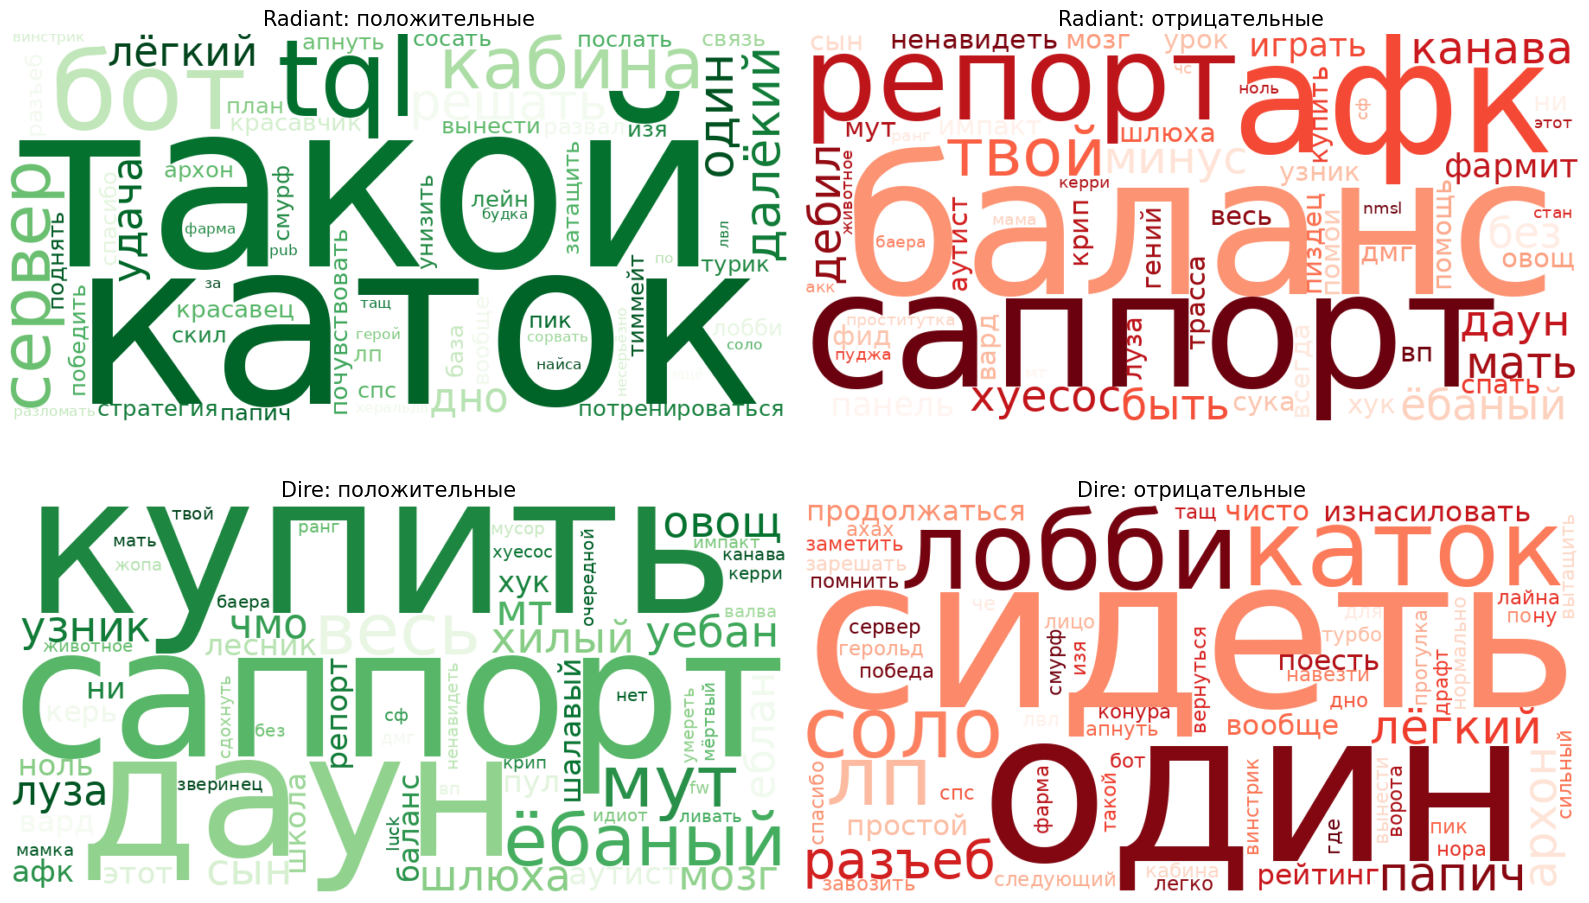

In [12]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

from wordcloud import WordCloud
from matplotlib import font_manager
import matplotlib.pyplot as plt

# Получаем все коэффициенты модели
coef = model.coef_[0]

# Смещения текстовых признаков
r_start = X_base_train.shape[1]
d_start = r_start + X_r_train.shape[1]

r_words = vectorizer_r.get_feature_names_out()
d_words = vectorizer_d.get_feature_names_out()

r_coef = coef[r_start:d_start]
d_coef = coef[d_start:d_start + len(d_words)]


def top_words(words, weights, positive=True, n=60):
    order = np.argsort(weights)

    if positive:
        order = order[::-1]

    result = {}

    for i in order:
        value = float(weights[i])

        if positive and value <= 0:
            break
        if not positive and value >= 0:
            break

        # Для читаемости оставим слова с
        # латинскими или кириллическими буквами
        if not re.search(r'[a-zа-яё]', words[i]):
            continue

        result[str(words[i])] = abs(value)

        if len(result) >= n:
            break

    return result


clouds = [
    ('Radiant: положительные', top_words(r_words, r_coef, True)),
    ('Radiant: отрицательные', top_words(r_words, r_coef, False)),
    ('Dire: положительные', top_words(d_words, d_coef, True)),
    ('Dire: отрицательные', top_words(d_words, d_coef, False))
]

font_path = font_manager.findfont('DejaVu Sans')

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

for i, (title, frequencies) in enumerate(clouds):
    ax = axes.flat[i]

    cloud = WordCloud(
        width=900,
        height=450,
        background_color='white',
        font_path=font_path,
        max_words=60,
        collocations=False,
        colormap='Greens' if i % 2 == 0 else 'Reds'
    )

    cloud.generate_from_frequencies(frequencies)

    ax.imshow(cloud, interpolation='bilinear')
    ax.set_title(title, fontsize=15)
    ax.axis('off')

plt.tight_layout()
plt.show()


<div style="border-left: 5px solid #ff748c; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** что думаете? Сейчас и вообще по модели — негативные получились слова или так, едва?

**Ответ:**

)))))

In [13]:
"""
Хочу снова добавить фичи героев и посмотреть.
Весь код этой cell уже был в первой части.
"""

test_df = pd.read_csv('matches_df_test.csv')

players_raw = pd.read_csv('player_df.csv')
heroes_df = pd.read_csv('Constants.Heroes.csv')

print('Players:', players_raw.shape)
print('Heroes:', heroes_df.shape)

display(players_raw.sample(3))
display(heroes_df.sample(3))

print(players_raw['account_id'].value_counts(dropna=False).head(15))
print('Missing account_id:', players_raw['account_id'].isna().sum())

p = players_raw.copy()

print('Duplicate heroes:')
duplicate_heroes = p.duplicated(
    ['match_id', 'hero_id'],
    keep=False,
)
print('Unique matches with duplicate heroes:', p.loc[duplicate_heroes, 'match_id'].nunique())
print('Matches with duplicate heroes:', duplicate_heroes.sum())

print('\nPlayers with hero_id=0:')
display(
    p.loc[p['hero_id'] == 0, 'account_id']
    .value_counts()
)

valid_hero_ids = sorted(
    heroes_df['id'].dropna().astype(int).unique()
)

p['side'] = np.select(
    [
        p['player_slot'].between(0, 4),
        p['player_slot'].between(128, 132)
    ],
    [1, -1],
    default=0
)

bad_matches = set()

# Неверные и отстутвующие герои
bad_matches.update(
    p.loc[~p['hero_id'].isin(valid_hero_ids), 'match_id']
)

# Duplicated heroes and player slots
bad_matches.update(p.loc[duplicate_heroes, 'match_id'])
bad_matches.update(
    p.loc[
        p.duplicated(['match_id', 'player_slot'], keep=False),
        'match_id'
    ]
)

# Incorrect sides
bad_matches.update(p.loc[p['side'] == 0, 'match_id'])

suspicious_ids = {0, -1, 4294967295}

known_players = p.loc[
    p['account_id'].notna()
    & ~p['account_id'].isin(suspicious_ids)
    & (p['side'] != 0)
]

side_counts = known_players.groupby(
    ['match_id', 'account_id']
)['side'].nunique()

bad_matches.update(
    side_counts[side_counts > 1]
    .index.get_level_values('match_id')
)

all_match_ids = pd.Index(train_df['match_id']).append(
    pd.Index(test_df['match_id'])
)

p = p.loc[
    p['match_id'].isin(all_match_ids)
    & ~p['match_id'].isin(bad_matches)
].copy()

counts = p.groupby(['match_id', 'side']).size().unstack(fill_value=0)

good_match_ids = counts.index[
    (counts[1] == 5)
    & (counts[-1] == 5)
]

print(good_match_ids.shape)

players_clean = p.loc[p['match_id'].isin(good_match_ids)].copy()
display(players_clean.sample(3))

check = players_clean.groupby(
    ['match_id', 'side']
).size().unstack(fill_value=0)

assert (check[1] == 5).all()
assert (check[-1] == 5).all()
assert not players_clean.duplicated(['match_id', 'hero_id']).any()


print('Корректных матчей:', players_clean['match_id'].nunique())
print('Оставшихся игроков:', len(players_clean))
print('Доля train с героями:',
      train_df['match_id'].isin(good_match_ids).mean())
print('Доля test с героями:',
      test_df['match_id'].isin(good_match_ids).mean())


from scipy.sparse import csr_array, csr_matrix  # вам может понравиться

class HeroesEncoder:
    def __init__(self, players, hero_ids):
      self.players = players[['match_id', 'hero_id', 'side']].copy()
      self.hero_ids = list(hero_ids)

    def fit(self, X, y=None):
        self.hero_to_col = {
            hero_id: i
            for i, hero_id in enumerate(self.hero_ids)
        }
        return self

    def transform(self, X, y=None):
        match_ids = X['match_id'].to_numpy()

        # Номер строки для каждого матча
        row_lookup = pd.Series(
            np.arange(len(match_ids)),
            index=match_ids
        )

        current = self.players.loc[
            self.players['match_id'].isin(match_ids)
        ]

        rows = current['match_id'].map(row_lookup).to_numpy()
        hero_cols = current['hero_id'].map(self.hero_to_col)

        valid = hero_cols.notna()

        return csr_matrix(
            (
                current.loc[valid, 'side'].to_numpy(),
                (
                    rows[valid].astype(int),
                    hero_cols[valid].to_numpy(dtype=int)
                )
            ),
            shape=(len(match_ids), len(self.hero_ids)),
            dtype=np.float32
        )

hero_encoder = HeroesEncoder(
    players_clean,
    valid_hero_ids,
).fit(train_df[['match_id']])

X_heroes_tr = hero_encoder.transform(
    train_df.loc[train_mask, ['match_id']]
)

X_heroes_val = hero_encoder.transform(
    train_df.loc[valid_mask, ['match_id']]
)

print("Train shape:", X_heroes_tr.shape)
print('Validation shape:', X_heroes_val.shape)

print('Значения:', np.unique(X_heroes_tr.data))

# print(X_heroes_tr.getrow(2))
print(X_heroes_tr.getrow(2).toarray().ravel())


Players: (7650825, 14)
Heroes: (126, 34)


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id
6829653,2,104590961,26,4.0,7.0,7.0,847.0,19.0,4.0,321.0,465.0,5492.0,52.0,141310
2080196,0,3918633,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,343817
2073113,4,4294967295,5,8.0,4.0,17.0,1043.0,124.0,10.0,436.0,490.0,11800.0,1176.0,687995


,Unnamed: 0,id,name,primary_attr,attack_type,roles,img,icon,base_health,base_health_regen,base_mana,base_mana_regen,base_armor,base_mr,base_attack_min,base_attack_max,base_str,base_agi,base_int,str_gain,agi_gain,int_gain,attack_range,projectile_speed,attack_rate,base_attack_time,attack_point,move_speed,turn_rate,cm_enabled,legs,day_vision,night_vision,localized_name
61,61,63,npc_dota_hero_weaver,agi,Ranged,"['Carry', 'Escape']",/apps/dota2/images/dota_react/heroes/weaver.png?,/apps/dota2/images/dota_react/heroes/icons/wea...,120,1.25,75,0.50,1,25,37,43,16,17,20,2.0,3.3,2.0,425,900,1.8,120,0.55,275,NaN,True,4,1800,800,Weaver
83,83,85,npc_dota_hero_undying,str,Melee,"['Support', 'Durable', 'Disabler', 'Nuker']",/apps/dota2/images/dota_react/heroes/undying.png?,/apps/dota2/images/dota_react/heroes/icons/und...,120,NaN,75,0.25,1,25,31,39,22,10,27,2.4,1.2,2.8,150,900,1.7,100,0.30,300,NaN,True,2,1800,800,Undying
5,5,6,npc_dota_hero_drow_ranger,agi,Ranged,"['Carry', 'Disabler', 'Pusher']",/apps/dota2/images/dota_react/heroes/drow_rang...,/apps/dota2/images/dota_react/heroes/icons/dro...,120,0.25,75,0.00,0,25,29,36,16,22,15,1.9,2.9,1.4,625,1250,1.7,100,0.50,310,0.7,True,2,1800,800,Drow Ranger


account_id
 4294967295    2795673
-1               27267
 37619671          801
 84244723          763
 87266522          761
 38584608          752
 85427446          743
 62933415          742
 151993649         740
 137331734         735
 64800968          713
 49092801          707
 198434112         705
 10856368          702
 13934403          695
Name: count, dtype: int64
Missing account_id: 0
Duplicate heroes:
Unique matches with duplicate heroes: 1053
Matches with duplicate heroes: 4108

Players with hero_id=0:


,count
account_id,
4294967295,1091
85871774,27
125343075,18
68266729,18
82978252,17
...,...
187571852,1
105902963,1
119684865,1


(699675,)


,player_slot,account_id,hero_id,kills,deaths,assists,gold,last_hits,denies,gold_per_min,xp_per_min,hero_damage,tower_damage,match_id,side
1588548,129,4294967295,13,12.0,11.0,19.0,2299.0,260.0,8.0,411.0,456.0,17535.0,813.0,614090,-1
6677056,130,4294967295,78,6.0,11.0,13.0,181.0,179.0,3.0,343.0,497.0,11993.0,253.0,219968,-1
5882273,132,85335142,1,0.0,3.0,1.0,3.0,37.0,0.0,166.0,111.0,565.0,81.0,448894,-1


Корректных матчей: 699675
Оставшихся игроков: 6996750
Доля train с героями: 0.9983465660047731
Доля test с героями: 0.9982760929236125
Train shape: (582297, 126)
Validation shape: (58793, 126)
Значения: [-1.  1.]
[ 0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.
  0. -1. -1.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0. -1.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0. -1.  0.  0.  0.  0.  0.
 -1.  0.  0.  0.  0.  0.  0.  0.  0.  1.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]


In [14]:
X_train = hstack([
    X_train,
    X_heroes_tr
], format='csr')

X_valid = hstack([
    X_valid,
    X_heroes_val
], format='csr')

print('Train shape:', X_train.shape)
print('Valid shape:', X_valid.shape)

model = SGDClassifier(
    loss='log_loss',
    alpha=1e-5,
    max_iter=500,
    tol=1e-3,
    average=True,
    random_state=42,
    # verbose=1,
    n_iter_no_change=5,
)

model.fit(
    X_train,
    y[train_idx]
)

train_pred = model.decision_function(X_train)
valid_pred = model.decision_function(X_valid)

gini_train = gini(y[train_idx], train_pred)
gini_valid = gini(y[valid_idx], valid_pred)

print(f'Gini train: {gini_train:.6f}')
print(f'Gini valid: {gini_valid:.6f}')

Train shape: (582297, 8158)
Valid shape: (58793, 8158)
Gini train: 0.345084
Gini valid: 0.336407


### **Часть 5. Агрегации** (1.75 балла) <img align="center" src="https://static.wikia.nocookie.net/dota2_gamepedia/images/4/4a/Techies_emoticon.gif/revision/latest?cb=20180504014918">

В которой студент начинает ведать

#### 📈 **Задание 5.1. Статистики матча** (0.75 балла)

Есть у нас в данных большой кусок про advantage — преимущество команды сил Света с точностью до минуты, по золоту и опыту, всё так же **в пределах 15 минут**. Лежат они в `dota_adv.csv`. Чем больше число, тем больше шанс на победу — всё просто. Только график, как правило, не линеен.

С ними в очередной раз есть *нюансы* — необходимо разобраться, как они там лежат, и всё ли там в порядке со значениями, но это меньшая из проблем. А также нарисовать парочку advantage, чтобы было понимание, как они себя ведут

Для начала возьмём простые агрегации. Можете взять те, что вам знакомы (статистики - среднее, стд и др.), можете взять фан факты в вашей любимой библиотеке для данных, например [тут](https://pandas.pydata.org/docs/user_guide/groupby.html#aggregation) или [тут](https://docs.pola.rs/api/python/stable/reference/expressions/aggregation.html).

Задание:
- взять 4 статистики из библиотеки, применить к обеим колонкам `_adv`, <font color="#f68c9d">**обдумать**</font>, почему именно они
- одну из статистику выше разбить по командам, и точно так же примените к колонкам (получится что-то типа `agg_xp` -> `agg_dire_xp`, `agg_radiant_xp`)

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Тут мы встаём на скользкую дорожку переобучения. Агрегаций можно сделать **очень** много. Добавьте их все, и ваша модель превратится в тыкву. Удобнее будет сразу бить их на группы, например `features_last`, `features_q25`, `features_kurtosis_dire_10min+` и так далее, в зависимости от степени упоротости

C другой стороны, агрегации это самая сильная группа фичей, и для десяточки лучше целиться именно в них

</div>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** какие агрегации берём?

**Ответ:**

Берём четыре статистики: mean, std, min, max. Дополнительно добавляем преимущество в последнюю минуту и среднее преимущество каждой команды.

Среднее характеризует общее преимущество, стандартное отклонение - его изменчивость, минимум и максимум - крайние состояния, а последняя минута - наиболее актуальное положение команд

Обучите модель по агрегациям (одной группе или нескольким) + предыдущим фичам. Чтобы получить фулл балл, придётся показать, что хотя бы минимальный импрув есть, относительно бейзлайна

,match_id,radiant_gold_adv,radiant_exp_adv
619609,651081,[],[]
277070,519632,[ 0 44 -334 -360 -628 -1155 -1155 -11...,[ 0 -113 -264 -151 -495 -1040 -1040 -12...
150376,370419,[],[]
368995,303472,[],[]
312916,580483,[ 0 -646 -928 -512 -621 -738 -738 -535 -535 ...,[ 0 -223 -185 413 115 209 209 2...


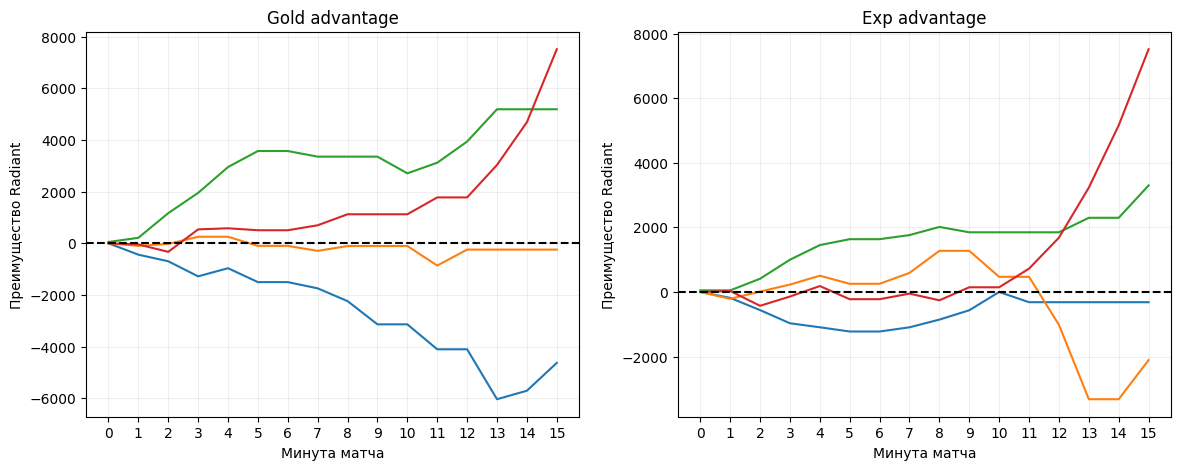

In [15]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

adv_df = pd.read_csv('dota_adv.csv')

display(adv_df.sample(5))

# Сопоставляем строки с train_df по 'match_id'
adv = (
  adv_df
  .set_index('match_id')
  .reindex(train_df['match_id'].to_numpy())
)

def parse_adv(value):
  if pd.isna(value) or value == '[]':
    return None

  arr = np.fromstring(
      value.strip('[]'), sep=' ', dtype=np.float32
  )

  # Убираем неккоректные последовательности
  if len(arr) != 16 or np.max(np.abs(arr)) >= 150000:
    return None

  return arr

def make_adv_matrix(column):
  matrix = np.full(
      (len(train_df), 16), np.nan, dtype=np.float32
  )

  for i, value in enumerate(adv[column]):
    arr = parse_adv(value)
    if arr is not None:
      matrix[i] = arr

  return matrix

gold = make_adv_matrix('radiant_gold_adv')
exp = make_adv_matrix('radiant_exp_adv')

sample_ids = np.flatnonzero(
    ~np.isnan(gold[:, -1])
)[:4]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for idx in sample_ids:
  axes[0].plot(range(16), gold[idx])
  axes[1].plot(range(16), exp[idx])

for ax, title in zip(
    axes, ['Gold advantage', 'Exp advantage']
):
  ax.axhline(0, color='black', linestyle='--')
  ax.set_xticks(np.arange(0, 16, 1))
  ax.set_xlabel('Минута матча')
  ax.set_ylabel('Преимущество Radiant')
  ax.set_title(title)
  ax.grid(alpha=0.2)

plt.show()

In [16]:
# has_adv = adv['radiant_gold_adv'].ne('[]').to_numpy().astype(int)
has_adv = np.isfinite(gold).any(axis=1).astype(int)
has_adv = has_adv.reshape(-1, 1)

import warnings

adv_features = pd.DataFrame(index=train_df.index)

adv_features['has_adv'] = has_adv.ravel()

for name, matrix in [('gold', gold), ('exp', exp)]:
  with warnings.catch_warnings():
    warnings.simplefilter('ignore', RuntimeWarning)

    adv_features[f'{name}_mean'] = np.nanmean(matrix, axis=1)
    adv_features[f'{name}_std'] = np.nanstd(matrix, axis=1)
    adv_features[f'{name}_min'] = np.nanmin(matrix, axis=1)
    adv_features[f'{name}_max'] = np.nanmax(matrix, axis=1)
    adv_features[f'{name}_last'] = matrix[:, -1]

    adv_features[f'{name}_radiant_mean'] = np.nanmean(
        np.where(matrix > 0, matrix, np.nan), axis=1
    )

    adv_features[f'{name}_dire_mean'] = np.nanmean(
        np.where(matrix < 0, -matrix, np.nan), axis=1
    )


# display(adv_features.sample(5))
print(adv_features.shape)


imputer = SimpleImputer(
    strategy='median',
    keep_empty_features=True
)

adv_train = imputer.fit_transform(
    adv_features.loc[train_mask]
)
adv_valid = imputer.transform(
    adv_features.loc[valid_mask]
)

scaler = StandardScaler()

adv_train = scaler.fit_transform(adv_train)
adv_valid = scaler.transform(adv_valid)


X_train = hstack([
    X_train,
    csr_matrix(adv_train)
], format='csr')

X_valid = hstack([
    X_valid,
    csr_matrix(adv_valid)
], format='csr')

print('Train shape:', X_train.shape)
print('Valid shape:', X_valid.shape)

(641090, 15)
Train shape: (582297, 8173)
Valid shape: (58793, 8173)


In [17]:

model = SGDClassifier(
    loss='log_loss',
    alpha=1e-5,
    max_iter=1000,
    tol=1e-3,
    average=True,
    random_state=42,
    verbose=1,
    n_iter_no_change=5,
)

model.fit(
    X_train,
    y[train_idx]
)

train_pred = model.decision_function(X_train)
valid_pred = model.decision_function(X_valid)

gini_train = gini(y[train_idx], train_pred)
gini_valid = gini(y[valid_idx], valid_pred)

print(f'Gini train: {gini_train:.6f}')
print(f'Gini valid: {gini_valid:.6f}')

-- Epoch 1
Norm: 52.02, NNZs: 8157, Bias: -0.355617, T: 582297, Avg. loss: 6.719957
Total training time: 0.32 seconds.
-- Epoch 2
Norm: 40.48, NNZs: 8157, Bias: -0.343590, T: 1164594, Avg. loss: 1.175816
Total training time: 0.65 seconds.
-- Epoch 3
Norm: 35.54, NNZs: 8157, Bias: -0.345006, T: 1746891, Avg. loss: 0.875680
Total training time: 0.97 seconds.
-- Epoch 4
Norm: 32.91, NNZs: 8157, Bias: -0.339631, T: 2329188, Avg. loss: 0.780277
Total training time: 1.29 seconds.
-- Epoch 5
Norm: 31.67, NNZs: 8157, Bias: -0.334651, T: 2911485, Avg. loss: 0.735076
Total training time: 1.61 seconds.
-- Epoch 6
Norm: 30.13, NNZs: 8157, Bias: -0.334474, T: 3493782, Avg. loss: 0.705623
Total training time: 1.96 seconds.
-- Epoch 7
Norm: 29.30, NNZs: 8157, Bias: -0.333340, T: 4076079, Avg. loss: 0.689020
Total training time: 2.28 seconds.
-- Epoch 8
Norm: 28.69, NNZs: 8157, Bias: -0.335765, T: 4658376, Avg. loss: 0.678077
Total training time: 2.60 seconds.
-- Epoch 9
Norm: 28.21, NNZs: 8157, Bias:

In [18]:
"""Another submission try"""

adv_scaler = scaler

test_df = pd.read_csv(
    'matches_df_test.csv',
    parse_dates=['date']
)

# 1. Базовые признаки
X_test_base_df = pd.DataFrame(index=test_df.index)

X_test_base_df['region'] = test_df['region'].fillna('Unknown')
X_test_base_df['day_of_week'] = test_df['date'].dt.dayofweek.astype(str)
X_test_base_df['match_day'] = test_df['date'].dt.day
X_test_base_df['month'] = test_df['date'].dt.month
X_test_base_df['is_weekend'] = (
    test_df['date'].dt.dayofweek >= 5
).astype(int)

X_test_base_df['mmr_log'] = np.log1p(
    test_df['avg_mmr'].clip(lower=0)
)
X_test_base_df['mmr_missing'] = test_df['avg_mmr'].isna().astype(int)

# 2. Текстовые признаки
chat_test = (
    chat_df
    .set_index('match_id')
    .reindex(test_df['match_id'].to_numpy())
    .reset_index(drop=True)
)

chat_test[['radiant_chat', 'dire_chat']] = (
    chat_test[['radiant_chat', 'dire_chat']].fillna('')
)

for side in ['radiant', 'dire']:
    text = chat_test[f'{side}_chat']

    X_test_base_df[f'{side}_has_chat'] = text.ne('').astype(int)
    X_test_base_df[f'{side}_messages'] = text.str.count(r'\|')
    X_test_base_df[f'{side}_chars'] = text.str.len()
    X_test_base_df[f'{side}_questions'] = text.str.count(r'\?')
    X_test_base_df[f'{side}_exclamations'] = text.str.count('!')

# Точно такой же порядок столбцов, как на train
X_test_base_df = X_test_base_df[X.columns]

X_base_test = csr_matrix(
    preprocessor.transform(X_test_base_df)
)

# 3. TF-IDF
radiant_test_texts = chat_test['radiant_chat'].map(
    lambda text: ' '.join(preprocessing(text))
)
dire_test_texts = chat_test['dire_chat'].map(
    lambda text: ' '.join(preprocessing(text))
)

X_r_test = vectorizer_r.transform(radiant_test_texts)
X_d_test = vectorizer_d.transform(dire_test_texts)

# 4. Герои
X_heroes_test = hero_encoder.transform(
    test_df[['match_id']]
)

print('Base:', X_base_test.shape)
print('Radiant TF-IDF:', X_r_test.shape)
print('Dire TF-IDF:', X_d_test.shape)
print('Heroes:', X_heroes_test.shape)



adv_test = (
    adv_df
    .set_index('match_id')
    .reindex(test_df['match_id'].to_numpy())
)

def make_adv_test_matrix(column):
    matrix = np.full(
        (len(test_df), 16),
        np.nan,
        dtype=np.float32
    )

    for i, value in enumerate(adv_test[column]):
        arr = parse_adv(value)

        if arr is not None:
            matrix[i] = arr

    return matrix


gold_test = make_adv_test_matrix('radiant_gold_adv')
exp_test = make_adv_test_matrix('radiant_exp_adv')

adv_test_features = pd.DataFrame(index=test_df.index)

adv_test_features['has_adv'] = (
    np.isfinite(gold_test).any(axis=1).astype(int)
)

for name, matrix in [('gold', gold_test), ('exp', exp_test)]:
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', RuntimeWarning)

        adv_test_features[f'{name}_mean'] = np.nanmean(matrix, axis=1)
        adv_test_features[f'{name}_std'] = np.nanstd(matrix, axis=1)
        adv_test_features[f'{name}_min'] = np.nanmin(matrix, axis=1)
        adv_test_features[f'{name}_max'] = np.nanmax(matrix, axis=1)
        adv_test_features[f'{name}_last'] = matrix[:, -1]

        adv_test_features[f'{name}_radiant_mean'] = np.nanmean(
            np.where(matrix > 0, matrix, np.nan),
            axis=1
        )

        adv_test_features[f'{name}_dire_mean'] = np.nanmean(
            np.where(matrix < 0, -matrix, np.nan),
            axis=1
        )

# Тот же порядок признаков
adv_test_features = adv_test_features[adv_features.columns]

# Те же imputer и scaler, что на train
adv_test_imputed = imputer.transform(adv_test_features)
adv_test_scaled = adv_scaler.transform(adv_test_imputed)

X_adv_test = csr_matrix(adv_test_scaled)

print('Advantage:', X_adv_test.shape)
print('NaN:', np.isnan(X_adv_test.data).sum())


X_test_final = hstack([
    X_base_test,
    X_r_test,
    X_d_test,
    X_heroes_test,
    X_adv_test
], format='csr')

print('Train features:', model.n_features_in_)
print('Test shape:', X_test_final.shape)

assert X_test_final.shape[0] == len(test_df)
assert X_test_final.shape[1] == model.n_features_in_
assert np.isfinite(X_test_final.data).all()

print('Матрица для submission готова')


from sklearn.base import clone

# Создаём полную матрицу train теми же преобразованиями
X_full = hstack([
    csr_matrix(preprocessor.transform(X[X.columns])),
    vectorizer_r.transform(radiant_texts),
    vectorizer_d.transform(dire_texts),
    hero_encoder.transform(train_df[['match_id']]),
    csr_matrix(
        adv_scaler.transform(
            imputer.transform(
                adv_features[adv_features.columns]
            )
        )
    )
], format='csr')

assert X_full.shape[1] == X_test_final.shape[1]
assert X_full.shape[1] == model.n_features_in_
assert np.isfinite(X_full.data).all()

# Новая модель с параметрами лучшей модели
final_model = clone(model)

final_model.fit(
    X_full,
    train_df['radiant_win'].astype(int).to_numpy()
)

print('Финальная модель обучена')



# Вероятность победы Radiant
predictions = final_model.predict_proba(
    X_test_final
)[:, list(final_model.classes_).index(1)]

submission = pd.DataFrame({
    'ID': test_df['match_id'],
    'Value': predictions
})

# Проверки
assert len(submission) == len(test_df)
assert submission['ID'].equals(test_df['match_id'])
assert submission['Value'].between(0, 1).all()
assert submission.notna().all().all()

display(submission.head())
print(submission['Value'].describe())

submission.to_csv('submission.csv', index=False)

print('submission.csv сохранён!')


Base: (59748, 32)
Radiant TF-IDF: (59748, 4000)
Dire TF-IDF: (59748, 4000)
Heroes: (59748, 126)
Advantage: (59748, 15)
NaN: 0
Train features: 8173
Test shape: (59748, 8173)
Матрица для submission готова
-- Epoch 1
Norm: 49.30, NNZs: 8157, Bias: -0.493795, T: 641090, Avg. loss: 6.317530
Total training time: 0.36 seconds.
-- Epoch 2
Norm: 38.85, NNZs: 8157, Bias: -0.459905, T: 1282180, Avg. loss: 1.101193
Total training time: 0.72 seconds.
-- Epoch 3
Norm: 34.33, NNZs: 8157, Bias: -0.467040, T: 1923270, Avg. loss: 0.846918
Total training time: 1.08 seconds.
-- Epoch 4
Norm: 31.90, NNZs: 8157, Bias: -0.453536, T: 2564360, Avg. loss: 0.760133
Total training time: 1.45 seconds.
-- Epoch 5
Norm: 30.36, NNZs: 8157, Bias: -0.451300, T: 3205450, Avg. loss: 0.720435
Total training time: 1.81 seconds.
-- Epoch 6
Norm: 29.32, NNZs: 8157, Bias: -0.453056, T: 3846540, Avg. loss: 0.694810
Total training time: 2.16 seconds.
-- Epoch 7
Norm: 28.53, NNZs: 8157, Bias: -0.449084, T: 4487630, Avg. loss: 0.

,ID,Value
0,8,0.357742
1,29,0.595853
2,34,0.774209
3,36,0.381729
4,61,0.567095


count    5.974800e+04
mean     4.739553e-01
std      2.374312e-01
min      1.585011e-12
25%      2.981957e-01
50%      4.689324e-01
75%      6.451954e-01
max      1.000000e+00
Name: Value, dtype: float64
submission.csv сохранён!


#### 📈 **Задание 5.2. Тренд** (0.5 балла)

Каждый уважающий себя лудоман знает, что 99% процентов игроков останавливается ровно перед тем, как сорвать джекпот. Так и здесь — если команда с треском проигрывает в первые 15 минут матча, возможно это признак камбека в следующие 50, как знать? Попробуем собрать агрегацию похитрее — она будет обозначать тренд, который есть в графиках преимущества, и если пословица верна, наша модель уловит эту зависимость.

<span style="color:grey"><font size="1">Администрация курса МО-1 категорически против азартных игр, пример приводится сугубо в образовательных целях.</font></span>

<div style="border-left: 5px solid #f68c9d; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(255, 116, 140, 0.05);">

**Вопрос:** для чего нам вообще тренд? Полезная ли это агрегация?

**Ответ:**

</div>

Агрегировать можно и вещи несколько более прикольные, чем те, что есть в основном функционале. Делать это мы будем, как вы наверняка догадались, трансформером, ну а чем же ещё. Что он умеет?

1. Принимает на вход функцию колонку и <font color="#cb9255">**параметры**</font> на ваш вкус, как минимум `method`, метод расчёта `slope`
2. Выделяет коэффициент наклона (`slope`, он же $\alpha$) при помощи одного из методов:
   - `'delta'`: разность первого и последнего значений $|x_{\max} - x_{\min}|$
   - `'OLS'`: линейная регрессия, обученная методом МНК $(X^TX)^{-1}X^Ty$
   - альтернативный метод, порождённый вашей бурной фантазией
3. Считает `r2` и `intercept` для одного advantage (если что это тоже могут быть наши фичи!)

In [19]:
from typing import Iterable
from sklearn.base import BaseEstimator, TransformerMixin

class TrendTransformer(BaseEstimator, TransformerMixin):

    def __init__(self, columns: Iterable[str] = ('gold', 'exp'), method='OLS'):
        self.columns = columns
        self.method = method

    def fit(self, X, y=None):
        return self

    def transform(self, X, y=None):
        # ヾ(⌐■_■)ノ♪ your code here
        result = pd.DataFrame()
        ts = np.arange(16, dtype=np.float32) # (16,)

        for col in self.columns:
          arr = X[col] # (N, 16)

          # булев массив - есть ли валидные точки
          valid = ~np.isnan(arr[:, -1]) # (N,)

          # среднее по времени для каждого матча
          mean = np.nanmean(arr, axis=1) # (N,)

          if self.method == 'OLS':
            # t.mean() -> скаляр ()
            # t - t.mean() -> shape: (16,)
            # np.nan_to_num(arr) -> shape: (N, 16)
            # (N, 16) * (16,) -> broadcast -> shape: (N, 16)
            # .sum(axis=1) -> shape: (N,)
            # ((16,) ** 2).sum() -> скаляр ()
            num = (np.nan_to_num(arr, nan=0.0) * (ts - ts.mean())).sum(axis=1)
            denum = ((ts - ts.mean()) ** 2).sum()
            slope = num / denum # (N,)

          elif self.method == 'delta':
            # arr[:, -1] -> (N,), arr[:, 0] -> (N,)
            slope = (arr[:, -1] - arr[:, 0]) / 15 # (N,)
          else:
            raise ValueError("Unknown method")

          slope[~valid] = np.nan # зануляем (в NaN) не валидные матчи
          # (N,) - (N,) * scalar = (N,) * scalar
          intercept = mean - slope * ts.mean()

          # заполняем всю матрицу предикшенами
          predicted = (slope[:, None] * ts + intercept[:, None]) # (N, 16)

          # (N,)
          ss_res = np.nansum(
              (arr - predicted) ** 2, axis=1
          )
          # (N,)
          ss_tot = np.nansum(
              (arr - mean[:, None]) ** 2, axis=1
          )

          r2 = 1 - np.divide(
              ss_res, ss_tot,
              out=np.ones_like(ss_res), # (N,)
              where=ss_tot>0
          )
          r2[~valid] = np.nan

          result[f'{col}_slope'] = slope
          result[f'{col}_intercept'] = intercept
          result[f'{col}_r2'] = r2
          result[f'{col}_delta'] = arr[:, -1] - arr[:, 0]

        return result


In [20]:
transformer = TrendTransformer(method='OLS')

trend_features = transformer.fit_transform({
    'gold': gold,
    'exp': exp
})

trend_cols = trend_features.columns.tolist()

display(trend_features.sample(5))

print(f"{trend_features['gold_r2'].max():.6f}")
print(f"{trend_features['exp_r2'].max():.6f}")

/tmp/ipykernel_2441/3754527365.py:25: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(arr, axis=1) # (N,)
/tmp/ipykernel_2441/3754527365.py:25: RuntimeWarning: Mean of empty slice
  mean = np.nanmean(arr, axis=1) # (N,)


,gold_slope,gold_intercept,gold_r2,gold_delta,exp_slope,exp_intercept,exp_r2,exp_delta
136582,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
415574,-74.998528,289.676453,0.152348,-415.0,434.114716,-1598.360352,0.680746,7276.0
621643,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
550883,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
419829,-81.466179,-446.316162,0.101236,1536.0,295.774994,-1755.500000,0.534211,3406.0


0.980205
0.981212


Реализуйте трансформер. Критерий успеха, вновь, качество — фича должна помочь, хотя бы на долю пункта

In [21]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
def numeric_preprocessor():
  return make_pipeline(
      SimpleImputer(strategy='median', keep_empty_features=True),
      StandardScaler(),
  )

num_preprocessor = numeric_preprocessor()
num_preprocessor.fit(trend_features.iloc[train_idx], y[train_idx])
trend_features_train = csr_matrix(num_preprocessor.transform(trend_features.iloc[train_idx]))
trend_features_valid = csr_matrix(num_preprocessor.transform(trend_features.iloc[valid_idx]))

X_train = hstack([
    X_train,
    trend_features_train,
], format='csr')

X_valid = hstack([
    X_valid,
    trend_features_valid,
], format='csr')


model = SGDClassifier(
    loss='log_loss',
    alpha=1e-5,
    max_iter=1000,
    tol=1e-3,
    average=True,
    random_state=42,
    verbose=1,
    n_iter_no_change=5,
)

model.fit(
    X_train,
    y[train_idx]
)

train_pred = model.decision_function(X_train)
valid_pred = model.decision_function(X_valid)

gini_train = gini(y[train_idx], train_pred)
gini_valid = gini(y[valid_idx], valid_pred)

print(f'Gini train: {gini_train:.6f}')
print(f'Gini valid: {gini_valid:.6f}')

-- Epoch 1
Norm: 53.34, NNZs: 8165, Bias: -0.469718, T: 582297, Avg. loss: 7.809775
Total training time: 0.36 seconds.
-- Epoch 2
Norm: 41.70, NNZs: 8165, Bias: -0.458497, T: 1164594, Avg. loss: 1.320132
Total training time: 0.73 seconds.
-- Epoch 3
Norm: 36.49, NNZs: 8165, Bias: -0.455298, T: 1746891, Avg. loss: 0.943569
Total training time: 1.11 seconds.
-- Epoch 4
Norm: 33.71, NNZs: 8165, Bias: -0.448155, T: 2329188, Avg. loss: 0.824606
Total training time: 1.45 seconds.
-- Epoch 5
Norm: 32.31, NNZs: 8165, Bias: -0.443070, T: 2911485, Avg. loss: 0.764536
Total training time: 1.80 seconds.
-- Epoch 6
Norm: 30.67, NNZs: 8165, Bias: -0.441647, T: 3493782, Avg. loss: 0.727768
Total training time: 2.21 seconds.
-- Epoch 7
Norm: 29.78, NNZs: 8165, Bias: -0.440159, T: 4076079, Avg. loss: 0.705648
Total training time: 2.56 seconds.
-- Epoch 8
Norm: 29.10, NNZs: 8165, Bias: -0.441150, T: 4658376, Avg. loss: 0.690947
Total training time: 2.95 seconds.
-- Epoch 9
Norm: 28.57, NNZs: 8165, Bias:

In [22]:
print(X_train.shape)
print(X_valid.shape)

(582297, 8181)
(58793, 8181)


#### **📈 Задание 5.3. Бинаризация** (0.5 балла)

Ровно одну прикольную фишку для числовых признаков мы пока что не рассмотрели — бинаризацию. Если вы до неё уже догадались, то вы — гений, не думали на <font color="cb9255">**МОП**</font>? А если нет, суть такова:

1. Берём отрезок advantage и бьём его на несколько бинов
2. Бины можно использовать, как фичу саму по себе, а можно подсобрать внутри неё агрегации

<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Во-первых, ваша модель внезапно становится нелинейной, хоть и кусочной, это полный отвал \
Во-вторых, это простейший пример ансамбля, если бинаризовать таргет (но у нас, увы нет смысла, он дискретный). Нелинейность полезна почему — в первые минуты преимущество не так решает, как в последние. \
В-третьих, это фильтрует шумный сигнал, выбросы то отлетят в соответствующий бин

</div>

Попробуем? Бинаризуйте признаки advantage: занумеруйте их (сделайте категорию) и посчитайте побиновые агрегации

In [23]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
bins = [
    -np.inf, -8000, -4000, -2000, -1000,
    0, 1000, 2000, 4000, 8000, np.inf
]

bin_features = pd.DataFrame()

for name, arr in [('gold', gold), ('exp', exp)]:
  bin_features[f'{name}_lastbin'] = (
      pd.cut(
          pd.Series(arr[:, -1]),
          bins=bins,
          labels=False
      )
      .fillna(-1)
      .astype(int)
      .astype(str)
  )

  valid = np.isfinite(arr[:, -1])

  bin_features[f'{name}_dire_minutes'] = np.where(
      valid, (arr < 0).sum(axis=1), np.nan
  )

  bin_features[f'{name}_radiant_minutes'] = np.where(
      valid, (arr > 0).sum(axis=1), np.nan
  )



In [24]:
def categorical_preprocessor():
  return make_pipeline(
      OneHotEncoder(handle_unknown='ignore')
  )

cat_preprocessor = categorical_preprocessor()

cat_preprocessor.fit(bin_features.iloc[train_idx])

bin_features_train = csr_matrix(cat_preprocessor.transform(bin_features.iloc[train_idx]))
bin_features_valid = csr_matrix(cat_preprocessor.transform(bin_features.iloc[valid_idx]))

X_train = hstack([
    X_train,
    bin_features_train,
], format='csr')

X_valid = hstack([
    X_valid,
    bin_features_valid,
], format='csr')

p

model = SGDClassifier(
    loss='log_loss',
    alpha=1e-5,
    max_iter=1000,
    tol=1e-3,
    average=True,
    random_state=42,
    verbose=1,
    n_iter_no_change=5,
)

model.fit(
    X_train,
    y[train_idx]
)

train_pred = model.decision_function(X_train)
valid_pred = model.decision_function(X_valid)

gini_train = gini(y[train_idx], train_pred)
gini_valid = gini(y[valid_idx], valid_pred)

print(f'Gini train: {gini_train:.6f}')
print(f'Gini valid: {gini_valid:.6f}')

-- Epoch 1
Norm: 55.94, NNZs: 8259, Bias: 0.053712, T: 582297, Avg. loss: 8.696659
Total training time: 0.38 seconds.
-- Epoch 2
Norm: 43.11, NNZs: 8259, Bias: 0.054195, T: 1164594, Avg. loss: 1.413642
Total training time: 0.74 seconds.
-- Epoch 3
Norm: 37.58, NNZs: 8259, Bias: 0.053096, T: 1746891, Avg. loss: 0.989827
Total training time: 1.11 seconds.
-- Epoch 4
Norm: 34.56, NNZs: 8259, Bias: 0.053453, T: 2329188, Avg. loss: 0.851747
Total training time: 1.47 seconds.
-- Epoch 5
Norm: 32.99, NNZs: 8259, Bias: 0.055762, T: 2911485, Avg. loss: 0.784119
Total training time: 1.84 seconds.
-- Epoch 6
Norm: 31.26, NNZs: 8259, Bias: 0.055720, T: 3493782, Avg. loss: 0.743071
Total training time: 2.21 seconds.
-- Epoch 7
Norm: 30.29, NNZs: 8259, Bias: 0.054447, T: 4076079, Avg. loss: 0.717588
Total training time: 2.58 seconds.
-- Epoch 8
Norm: 29.54, NNZs: 8259, Bias: 0.052718, T: 4658376, Avg. loss: 0.701123
Total training time: 2.97 seconds.
-- Epoch 9
Norm: 28.98, NNZs: 8259, Bias: 0.05395

### **Часть 6. Около ML** (2 балла) <img height=25px width=35px align="center" src="https://media1.tenor.com/m/72ScVNgTGpYAAAAC/kaneki-tokyo-ghoul.gif"></img>

В которой студент жесточайше чиллит после пережитого ужаса

#### **Задание 6.1. Пайплайн** (0.5 балла)

Работать в ноутбуках становится экспоненциально тяжелее по мере разрастания модели. Чтобы немножко упорядочить хаос, вам предлагается засунуть всё в один пайплайн. Критерии:

- функция или класс (может понравиться `ColumnTransformer` и `Pipeline`)
- возможность нажать одну кнопку, чтобы запустить пайплайн, уйти пить пиво и вернуться к уже готовому submission для Kaggle
- возможность передать флаги (какие фичи добавляем) и параметры (если есть разные варианты сбора параметров)
- включает в себя все пункты, к которым вы прикоснулись в рамках домашнего задания

А вот как именно это делать — дело ваше, для себя же стараетесь

In [36]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )
import numpy as np
import pandas as pd
import warnings

from scipy.sparse import csr_matrix, hstack
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier


class DotaPipeline:
    def __init__(
        self, chat_df, adv_df, hero_encoder=None,
        use_chat=True, use_heroes=True,
        use_adv=True, use_trend=True,
        use_bins=True, use_llm=False,
        max_text_features=4000, alpha=1e-5
    ):
        self.chat = chat_df.drop_duplicates('match_id').set_index('match_id')
        self.adv = adv_df.drop_duplicates('match_id').set_index('match_id')
        self.hero_encoder = hero_encoder

        self.flags = dict(
            chat=use_chat,
            heroes=use_heroes,
            adv=use_adv,
            trend=use_trend,
            bins=use_bins,
            llm=use_llm
        )
        self.max_text_features = max_text_features
        self.alpha = alpha

    def _base(self, df, chats):
        dt = pd.to_datetime(df['date'])
        out = pd.DataFrame(index=np.arange(len(df)))

        out['region'] = df['region'].fillna('Unknown').to_numpy()
        out['day_of_week'] = dt.dt.dayofweek.astype(str).to_numpy()
        out['match_day'] = dt.dt.day.to_numpy()
        out['month'] = dt.dt.month.to_numpy()
        out['is_weekend'] = (dt.dt.dayofweek >= 5).astype(int).to_numpy()
        out['mmr_log'] = np.log1p(df['avg_mmr'].clip(lower=0).to_numpy())
        out['mmr_missing'] = df['avg_mmr'].isna().astype(int).to_numpy()

        if chats is not None:
            for side in ('radiant', 'dire'):
                text = chats[f'{side}_chat']
                out[f'{side}_has_chat'] = text.ne('').astype(int).to_numpy()
                out[f'{side}_messages'] = text.str.count(r'\|').to_numpy()
                out[f'{side}_chars'] = text.str.len().to_numpy()
                out[f'{side}_questions'] = text.str.count(r'\?').to_numpy()
                out[f'{side}_exclamations'] = text.str.count('!').to_numpy()

        return out

    @staticmethod
    def _parse(value):
        if not isinstance(value, str) or value.strip() == '[]':
            return None

        arr = np.fromstring(
            value.strip('[]'), sep=' ', dtype=np.float32
        )

        if (
            len(arr) != 16
            or not np.isfinite(arr).all()
            or np.max(abs(arr)) >= 150000
        ):
            return None

        return arr

    def _adv_matrices(self, df):
        aligned = self.adv.reindex(df['match_id'].to_numpy())
        arrays = {}

        for name, column in [
            ('gold', 'radiant_gold_adv'),
            ('exp', 'radiant_exp_adv')
        ]:
            a = np.full(
                (len(df), 16), np.nan, dtype=np.float32
            )

            for i, value in enumerate(aligned[column]):
                parsed = self._parse(value)
                if parsed is not None:
                    a[i] = parsed

            arrays[name] = a

        return arrays

    @staticmethod
    def _stats(arrays):
        out = pd.DataFrame()
        out['has_adv'] = np.isfinite(
            arrays['gold']
        ).any(axis=1).astype(int)

        with warnings.catch_warnings():
            warnings.simplefilter('ignore', RuntimeWarning)

            for name, a in arrays.items():
                out[f'{name}_mean'] = np.nanmean(a, axis=1)
                out[f'{name}_std'] = np.nanstd(a, axis=1)
                out[f'{name}_min'] = np.nanmin(a, axis=1)
                out[f'{name}_max'] = np.nanmax(a, axis=1)
                out[f'{name}_last'] = a[:, -1]
                out[f'{name}_radiant_mean'] = np.nanmean(
                    np.where(a > 0, a, np.nan), axis=1
                )
                out[f'{name}_dire_mean'] = np.nanmean(
                    np.where(a < 0, -a, np.nan), axis=1
                )

        return out

    @staticmethod
    def _trends(arrays):
        t = np.arange(16, dtype=np.float64)
        out = pd.DataFrame()

        for name, a in arrays.items():
            a = a.astype(np.float64)
            available = np.isfinite(a).all(axis=1)

            with warnings.catch_warnings():
                warnings.simplefilter('ignore', RuntimeWarning)
                avg = np.nanmean(a, axis=1)

            slope = (
                np.nan_to_num(a) * (t - t.mean())
            ).sum(axis=1) / np.square(t - t.mean()).sum()

            slope[~available] = np.nan
            intercept = avg - slope * t.mean()
            fitted = intercept[:, None] + slope[:, None] * t

            ss_res = np.nansum(np.square(a - fitted), axis=1)
            ss_tot = np.nansum(np.square(a - avg[:, None]), axis=1)

            r2 = np.ones(len(a))
            np.divide(
                ss_res, ss_tot, out=r2,
                where=ss_tot > 0
            )
            r2 = 1 - r2
            r2[~available] = np.nan

            out[f'{name}_slope'] = slope
            out[f'{name}_intercept'] = intercept
            out[f'{name}_r2'] = r2
            out[f'{name}_delta'] = a[:, -1] - a[:, 0]

        return out

    @staticmethod
    def _bins(arrays):
        breaks = [
            -np.inf, -8000, -4000, -2000, -1000,
            0, 1000, 2000, 4000, 8000, np.inf
        ]
        out = pd.DataFrame()

        for name, a in arrays.items():
            labels = pd.cut(
                a[:, -1], bins=breaks, labels=False
            )

            out[f'{name}_lastbin'] = (
                pd.Series(labels)
                .fillna(-1).astype(int).astype(str)
            )

            valid = np.isfinite(a[:, -1])

            out[f'{name}_dire_minutes'] = np.where(
                valid, (a < 0).sum(axis=1), -1
            ).astype(str)

            out[f'{name}_radiant_minutes'] = np.where(
                valid, (a > 0).sum(axis=1), -1
            ).astype(str)

        return out

    def make_features(self, df, fit=False):
        chats = None

        if self.flags['chat']:
            chats = (
                self.chat
                .reindex(df['match_id'].to_numpy())[['radiant_chat', 'dire_chat']]
                .fillna('')
                .reset_index(drop=True)
            )
        base = self._base(df, chats)
        cats = ['region', 'day_of_week']
        nums = [c for c in base.columns if c not in cats]

        if fit:
            self.base_preprocessor_ = ColumnTransformer([
                ('cat', OneHotEncoder(handle_unknown='ignore'), cats),
                ('num', make_pipeline(
                    SimpleImputer(strategy='median'),
                    StandardScaler()
                ), nums)
            ])

        base_matrix = (
            self.base_preprocessor_.fit_transform(base)
            if fit else self.base_preprocessor_.transform(base)
        )

        features = {'base': csr_matrix(base_matrix)}

        if self.flags['chat']:
            chat_matrices = []

            for side in ('radiant', 'dire'):
                texts = chats[f'{side}_chat'].map(
                    lambda t: ' '.join(preprocessing(t))
                )

                if fit:
                    setattr(
                        self,
                        f'vectorizer_{side}_',
                        TfidfVectorizer(
                            max_features=self.max_text_features,
                            min_df=5,
                            ngram_range=(1,2),
                            sublinear_tf=True,
                            dtype=np.float32
                        )
                    )

                vectorizer = getattr(
                    self, f'vectorizer_{side}_'
                )

                chat_matrices.append(
                    vectorizer.fit_transform(texts)
                    if fit else vectorizer.transform(texts)
                )

            features['chat'] = hstack(chat_matrices, format='csr')

        if self.flags['heroes']:
            if self.hero_encoder is None:
                raise ValueError('Нужен hero_encoder')

            features['heroes'] = csr_matrix(
                self.hero_encoder.transform(df[['match_id']])
            )

        if any(
            self.flags[key]
            for key in ('adv', 'trend', 'bins', 'llm')
        ):
            arrays = self._adv_matrices(df)

            if self.flags['adv']:
                stats = self._stats(arrays)

                if fit:
                    self.adv_preprocessor_ = make_pipeline(
                        SimpleImputer(
                            strategy='median',
                            keep_empty_features=True
                        ),
                        StandardScaler()
                    )

                v = (
                    self.adv_preprocessor_.fit_transform(stats)
                    if fit
                    else self.adv_preprocessor_.transform(stats)
                )
                features['adv'] = csr_matrix(v)

            if self.flags['trend']:
                trends = self._trends(arrays)

                if fit:
                    self.trend_preprocessor_ = make_pipeline(
                        SimpleImputer(
                            strategy='median',
                            keep_empty_features=True
                        ),
                        StandardScaler()
                    )

                v = (
                    self.trend_preprocessor_.fit_transform(trends)
                    if fit
                    else self.trend_preprocessor_.transform(trends)
                )
                features['trend'] = csr_matrix(v)

            if self.flags['bins']:
                bins = self._bins(arrays)

                if fit:
                    self.bin_preprocessor_ = OneHotEncoder(
                        handle_unknown='ignore'
                    )

                v = (
                    self.bin_preprocessor_.fit_transform(bins)
                    if fit
                    else self.bin_preprocessor.transform(bins)
                )
                features['bins'] = csr_matrix(v)

            if self.flags['llm']:
                new_features = self._llm(arrays)

                if fit:
                    self.llm_preprocessor_ = make_pipeline(
                        SimpleImputer(
                            strategy='median',
                            keep_empty_features=True
                        ),
                        StandardScaler()
                    )

                v = (
                    self.llm_preprocessor_.fit_transform(new_features)
                    if fit
                    else self.llm_preprocessor_.transform(new_features)
                )
                features['llm'] = csr_matrix(v)

        return features

    @staticmethod
    def stack(features):
        matrix = hstack(list(features.values()), format='csr')

        if not np.isfinite(matrix.data).all():
            raise ValueError('В признаках остались NaN или inf')

        return matrix

    def fit(self, df, y):
        features = self.make_features(df, fit=True)
        X = self.stack(features)

        self.model = SGDClassifier(
            loss='log_loss',
            alpha=self.alpha,
            max_iter=500,
            tol=1e-3,
            average=True,
            random_state=42,
            verbose=1
        )

        self.model.fit(X, np.asarray(y).astype(int))
        self.train_shape_ = X.shape

        return self

    def predict_proba(self, df):
        X = self.stack(
            self.make_features(df, fit=False)
        )

        class_index = list(self.model.classes_).index(1)
        return self.model.predict_proba(X)[:, class_index]

    def create_submission(self, test_df, filename='submission.csv'):
        predictions = self.predict_proba(test_df)

        result = pd.DataFrame({
            'ID': test_df['match_id'].to_numpy(),
            'Value': predictions
        })

        assert len(result) == len(test_df)
        assert result['Value'].between(0, 1).all()

        result.to_csv(filename, index=False)
        return result


In [37]:

train_part = train_df.loc[train_mask].copy()
valid_part = train_df.loc[valid_mask].copy()

y_train = y[train_idx]
y_valid = y[valid_idx]

pipeline_args = dict(
    chat_df=chat_df,
    adv_df=adv_df,
    hero_encoder=hero_encoder
)

feature_flags = dict(
    use_chat=True,
    use_heroes=True,
    use_adv=True,
    use_trend=False,
    use_bins=False,
    use_llm=False
)

pipeline = DotaPipeline(
    **pipeline_args,
    **feature_flags
)

pipeline.fit(train_part, y_train)

valid_predictions = pipeline.predict_proba(valid_part)
pipeline_gini = gini(y_valid, valid_predictions)

print('Train matrix:', pipeline.train_shape_)
print(f'Validation Gini: {pipeline_gini:.6f}')


-- Epoch 1
Norm: 52.02, NNZs: 8157, Bias: -0.355617, T: 582297, Avg. loss: 6.719957
Total training time: 0.33 seconds.
-- Epoch 2
Norm: 40.48, NNZs: 8157, Bias: -0.343590, T: 1164594, Avg. loss: 1.175816
Total training time: 0.79 seconds.
-- Epoch 3
Norm: 35.54, NNZs: 8157, Bias: -0.345006, T: 1746891, Avg. loss: 0.875680
Total training time: 1.51 seconds.
-- Epoch 4
Norm: 32.91, NNZs: 8157, Bias: -0.339631, T: 2329188, Avg. loss: 0.780277
Total training time: 2.02 seconds.
-- Epoch 5
Norm: 31.67, NNZs: 8157, Bias: -0.334651, T: 2911485, Avg. loss: 0.735076
Total training time: 2.54 seconds.
-- Epoch 6
Norm: 30.13, NNZs: 8157, Bias: -0.334474, T: 3493782, Avg. loss: 0.705623
Total training time: 2.87 seconds.
-- Epoch 7
Norm: 29.30, NNZs: 8157, Bias: -0.333340, T: 4076079, Avg. loss: 0.689020
Total training time: 3.20 seconds.
-- Epoch 8
Norm: 28.69, NNZs: 8157, Bias: -0.335765, T: 4658376, Avg. loss: 0.678077
Total training time: 3.52 seconds.
-- Epoch 9
Norm: 28.21, NNZs: 8157, Bias:

In [38]:

def run_submission(flags, filename='submission_6_1.csv'):
    train_data = pd.read_csv(
        'matches_df_train.csv', parse_dates=['date']
    )
    test_data = pd.read_csv(
        'matches_df_test.csv', parse_dates=['date']
    )

    final_pipeline = DotaPipeline(
        **pipeline_args,
        **flags
    )

    final_pipeline.fit(
        train_data,
        train_data['radiant_win'].astype(int)
    )

    result = final_pipeline.create_submission(
        test_data, filename=filename
    )

    print('Submission shape:', result.shape)
    return final_pipeline, result


# Один вызов — обучение и создание submission
final_pipeline, submission = run_submission(
    feature_flags
)

display(submission.head())


-- Epoch 1
Norm: 49.55, NNZs: 8157, Bias: -0.355692, T: 641090, Avg. loss: 6.313278
Total training time: 0.39 seconds.
-- Epoch 2
Norm: 38.89, NNZs: 8157, Bias: -0.325632, T: 1282180, Avg. loss: 1.095783
Total training time: 0.77 seconds.
-- Epoch 3
Norm: 34.34, NNZs: 8157, Bias: -0.335118, T: 1923270, Avg. loss: 0.844495
Total training time: 1.17 seconds.
-- Epoch 4
Norm: 31.90, NNZs: 8157, Bias: -0.322937, T: 2564360, Avg. loss: 0.758584
Total training time: 1.56 seconds.
-- Epoch 5
Norm: 30.35, NNZs: 8157, Bias: -0.321786, T: 3205450, Avg. loss: 0.719405
Total training time: 1.94 seconds.
-- Epoch 6
Norm: 29.32, NNZs: 8157, Bias: -0.324567, T: 3846540, Avg. loss: 0.694073
Total training time: 2.31 seconds.
-- Epoch 7
Norm: 28.53, NNZs: 8157, Bias: -0.321431, T: 4487630, Avg. loss: 0.679726
Total training time: 2.70 seconds.
-- Epoch 8
Norm: 27.98, NNZs: 8157, Bias: -0.319228, T: 5128720, Avg. loss: 0.671741
Total training time: 3.07 seconds.
-- Epoch 9
Norm: 27.55, NNZs: 8157, Bias:

,ID,Value
0,8,0.356154
1,29,0.598442
2,34,0.776151
3,36,0.382686
4,61,0.575343


#### **Задание 6.2. Storage** (0.25 балла)

Вдогоночку можно ещё и создать псевдо-БД, чтобы хранить наши шедевры и не потеряться в тысячах моделек. Давайте вот такую штуку запилим:

- датафрейм или честная БД для версионирования моделей
- для каждой модели есть уникальный идентификатор
- для каждой модели сохраняются её гиперпараметры или параметры всего пайплайна (если вы его сделали)
- для каждой модели хранятся метрики на валидации

Сделайте и продемонстрируйте

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

#### **Задание 6.3. CuML** (0.25 балла)

Если вы таки осмелились делать домашку именно на Kaggle, то поздравляю, пожалуй, это самое здравое решение в этой дз. Чтобы использовать его возможности по полной, пересядьте с вашей модели из `sklearn`, которую вы выбрали в задании про даты **(1.3)**, на модель из `cuml`.

[Разберитесь](https://docs.rapids.ai/api/cuml/stable/), как они используют GPU и проведите тест-драйв на любом наборе фичей

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

#### **Задание 6.4. High tech. Low life** (0.5 балла)

Если вы следите за новостями, то, наверное, заметили появление хайповейших LLM. Злые языки утверждают, что обычному работяге фит предиктору не место в мире будущего, и его заменит ИИ. Давайте в этом (раз)убедимся.

Попробуйте:
1. Спросить у вашей любимой нейросети, какие признаки она может для вас придумать. Можете опираться на пункты выше, можете придумать что-то свое. Но помните, что как говорится, какой стол, такой и стул, поэтому пишите промпты с умом.
2. Показать, что нейросеть вам посоветовала, и реализовать это
3. Проанализировать результат и сделать решительный вывод, хуже ли вы, чем языковая модель.

Попытайтесь либо вспомнить, либо посмотреть, что у нас ещё есть в данных. Там достаточно много полезной информации, которую мы либо совсем никак не брали, либо брали, но поверхностно, либо брали, но можно сделать ещё круче, старые пункты тоже можно доработать

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

#### **Задание 6.5. Отбор признаков** (0.5 балла)

Когда признаков становится так много, что ваша оперативка начинает рыдать, а модель переобучается, как чёрт, поможет только одно средство — отбор фичей!
Это первое и единственное задание, в котором <font color="#cb9255">**выбора**</font> аж три:

<table width="100%" border="1" cellpadding="8" cellspacing="0">
  <tr>
    <th width="33%">
      <font color="#cb9255">Sequential Feature Selector</font>
    </th>
    <th width="33%">
      <font color="#cb9255">Greedy Selection</font>
    </th>
    <th width="33%">
      <font color="#cb9255">Recursive Feature Elimination</font>
    </th>
  </tr>
  <tr>
    <td valign="top">
      Делаем итеративно. На каждой итерации <br>
      оцениваем важность фичей по их <br>
      импортансу (<code>coef_</code>), берём <br>
      топ‑n худших, выкидываем, go to 0.
    </td>
    <td valign="top">
      Перебираем все комбинации признаков <br>
      и выбираем наилучшую. Звучит тупо, <br>
      но комбинации можно брать по группам <br>
      (например, тексты, агрегации средних <br>
      и т.д.), тогда это не так долго <br>
      <b>(2 часа на 200 признаков)</b>.
    </td>
    <td valign="top">
      Идём с конца и выкидываем по признаку. <br>
      На каждом шаге обучаем по одной модели <br>
      без одного признака (обучаем d‑1 моделей), <br>
      выбираем из них худшую — такой признак <br>
      и устраняем.
    </td>
  </tr>
  <tr>
    <td valign="top">
      Быстро <b>(около 20 минут <br>
      на 200 фичах)</b>, но веса линейной <br>
      регрессии плохо оценивают важность <br>
      фичей; это лучше работает для <br>
      сильных моделей.
    </td>
    <td valign="top">
      Не теряем интеракции. Баланс <br>
      скорость–качество.
    </td>
    <td valign="top">
      Возмутительно долго <b>(10 часов <br>
      на 200 признаков)</b>, но гарантирует <br>
      минимальные потери в качестве.
    </td>
  </tr>
</table>


<div style="border-left: 5px solid #647cb8; padding: 10px 20px 2px; margin: 15px 0 15px 20px; max-width: 800px; background-color: rgba(95, 121, 179, 0.05);">

Это улучшит качество, если вы уже страдаете от миллиарда малополезных фичей. Но для получения балла это не нужно, только верный алгоритм

</div>

Сделайте что-нибудь из этого и проанализируйте эффект. Не стесняйтесь модифицировать схему — удалять по несколько фичей за шаг, параллелить и так далее, пункт времязатратный

In [ ]:
# (´-`）.｡oO( ... YOUR CODE HERE ... )

### Заключение и оценивание

Каждая из задач в ноутбуке имеет свою стоимость (указана в скобках рядом с задачей). При этом важно уточнить разницу между баллами за ноутбук и дополнительными баллами за позицию на приватном лидерборде в соревновании на Kaggle:

1. **Максимум за код/ноутбуки — 8.0 баллов.**
   То есть, независимо от суммарной теоретической суммы всех подпунктов в тексте задания, за реализацию в ноутбуке можно получить не более 8 баллов (6 за базу и 2 за продвинутый).

2. **Максимально возможная оценка за всю работу — 13.0 баллов.**
   Остальные до 5.0 баллов начисляются за результаты в соревновании на Kaggle (лидерборд), при выполненном и загруженном в систему Anytask ноутбуке.

Баллы за сореву состоят из трёх частей: трешхолды (до 2 баллов), процентильный бонус (до 2.0 баллов) и бонус за попадание в топ-10 (до 1.0 балла). Суммарный вклад соревнования не может превышать 5.0 баллов.

**A. Процентильный балл (не суммируется):**
* Если вы пробили трешхолд-9 (качество 0.34) — +1 балл.
* Если вы пробили трешхолд-10 (качество 0.36) — +2 балла.

**Б. Процентильный балл:**

* Если вы только прошли трешхолд-10, то баллов вы не получите.
* Если вы обогнали ≥ 10% участников, побивших трешхолд-10 — +0.5 балла.
* Если вы обогнали ≥ 30% участников — +1.0 балла.
* Если вы обогнали ≥ 60% участников — +1.5 балла.
* Если вы обогнали ≥ 90% участников (т.е. попали в топ 10%) — +2.0 балла.

**В. Балл за попадание в топ-10:**

* 1-е место — +1.00 балла
* 2-е–3-е место — +0.75 балла
* 4-е–6-е место — +0.50 балла
* 7-е–10-е место — +0.25 балла

Пример расчёта

* Вы сделали ноутбуки и получили за них 7.0 / 8.0.
* Вы, тем не менее, побили трешхолд-10 → +2.0
* На лидерборде вы, зайка, обогнали 10% участников, побивших трешхолд 10 → процентильный бонус +2.0.
* Ваша позиция — 3-е место → топ-10 бонус +0.75.
* Итого: 7.0 + 2.0 + 2.0 + 0.75 = 11.75.

Можете свериться с картинкой (левая граница не включительно)

<img src="https://i.postimg.cc/nhb25b42/newplot.png" height=720 width=1280>

**Требование к воспроизводимости**

Баллы за соревнование начисляются **только** при наличии пайплайна или ноутбука, который подтверждает результат лучшего сабмита. Такое решение нужно сдавать вместе с базовым и продвинутым ноутбуками и своим ников в kaggle в Anytask ассистенту. Он должен выполнять всё автоматически при запуске ноутбука: при последовательном исполнении всех ячеек ноутбука (без ручных вмешательств) он должен воспроизвести предобработку, обучение/инференс и сгенерировать итоговый CSV-файл с прогнозами, используемый для сабмита.